<a href="https://colab.research.google.com/github/pandeyanjali1009/CommBank-Server/blob/main/Airbnb_NYC_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 🏠 Airbnb NYC Data Analysis (Python EDA)

**EDA** ka matlab hai *Exploratory Data Analysis* — yaani data ko dekhna, samajhna, saaf karna aur usme se useful baatein (insights) nikalna.

### Is project me tum kya seekhoge
1. Data load karna (Pandas)
2. Data ko samajhna (shape, info, describe)
3. Data cleaning (missing values, duplicates, outliers)
4. Questions puchna aur unke answers charts se dikhana
5. Business insights likhna

### Business problem
> Airbnb ek company hai jisme log apne ghar/room rent pe dete hain. Hum ek **Data Analyst** hain aur humein samajhna hai:
> kaunse area me kitni listings hain, price kaisi hai, kaunsa room type popular hai, aur hosts kaise perform kar rahe hain.

### Dataset
Kaggle: **New York City Airbnb Open Data** → file ka naam `AB_NYC_2019.csv`

### Tools
Python, Pandas, NumPy, Matplotlib, Seaborn

---
## Step 0️⃣ — Setup (sabse pehle yeh karo)

**Google Colab use karna sabse easy hai** (kuch install nahi karna padta):
1. colab.research.google.com kholo → *New notebook*
2. Is notebook ko upload karo (File → Upload notebook)
3. Kaggle se `AB_NYC_2019.csv` download karo
4. Neeche wala cell run karo (cell ke left me ▶ button dabao ya `Shift + Enter`)
5. Jab *Choose Files* button aaye, apni CSV file select karo

> 💡 **Cell kya hota hai?** Notebook chhote-chhote blocks ka bana hota hai. Code wale block ko cell kehte hain. Ek cell run karoge to uska output neeche dikhega.

In [2]:
# Agar Google Colab me ho to file upload karne ka button aayega.
# Agar apne laptop (Jupyter) pe ho to CSV file notebook ke same folder me rakh do.
try:
    from google.colab import files
    uploaded = files.upload()
except ImportError:
    print("Tum Colab me nahi ho. CSV file notebook ke same folder me honi chahiye.")

Saving AB_NYC_2019.csv to AB_NYC_2019 (1).csv


---
## Step 1️⃣ — Libraries import karna

**Library** = kisi ne pehle se likha hua code ka toolbox, jisko hum use kar sakte hain.

| Library | Kaam | Short name (alias) |
|---|---|---|
| pandas | Table jaisa data (Excel jaisa) handle karna | `pd` |
| numpy | Numbers aur maths | `np` |
| matplotlib | Charts banana | `plt` |
| seaborn | Sundar charts banana (matplotlib ke upar bana hai) | `sns` |

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Charts ko thoda sundar aur bada dikhane ke liye settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Warnings band kar rahe hain taaki output saaf dikhe
import warnings
warnings.filterwarnings("ignore")

print("Libraries ready ✅")

Libraries ready ✅


---
## Step 2️⃣ — Data load karna

`pd.read_csv()` CSV file ko padhkar ek **DataFrame** bana deta hai.
DataFrame = rows aur columns wali table, bilkul Excel sheet jaisi.
Hum usko `df` naam de rahe hain (df = data frame).

In [4]:
df = pd.read_csv("AB_NYC_2019.csv")
print("Data load ho gaya ✅")

Data load ho gaya ✅


---
## Step 3️⃣ — Data ko samajhna

Cleaning se pehle humein pata hona chahiye ki data me hai kya.

### 3.1 Pehli 5 rows dekho — `head()`

In [5]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


### 3.2 Columns ka matlab

| Column | Matlab |
|---|---|
| `id` | Listing ki unique ID |
| `name` | Listing ka naam/title |
| `host_id`, `host_name` | Jo insaan ghar rent pe de raha hai |
| `neighbourhood_group` | Bada area (Manhattan, Brooklyn, Queens, Bronx, Staten Island) |
| `neighbourhood` | Chhota area/mohalla |
| `latitude`, `longitude` | Location ke coordinates |
| `room_type` | Entire home / Private room / Shared room |
| `price` | Ek raat ka rent (USD me) |
| `minimum_nights` | Kam se kam kitni raat book karni hogi |
| `number_of_reviews` | Total reviews |
| `last_review` | Last review kab aaya |
| `reviews_per_month` | Mahine me average kitne reviews |
| `calculated_host_listings_count` | Us host ki total listings |
| `availability_365` | Saal me kitne din available hai |

### 3.3 Kitni rows aur columns hain — `shape`

In [6]:
print("Rows   :", df.shape[0])
print("Columns:", df.shape[1])

Rows   : 48895
Columns: 16


### 3.4 Column types aur missing values — `info()`

Yahan dekho:
- **Non-Null Count**: kitni values bhari hui hain (agar total rows se kam hai to us column me missing values hain)
- **Dtype**: data type (`int64` = poora number, `float64` = decimal number, `object` = text)

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  object 
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  object 
 4   neighbourhood_group             48895 non-null  object 
 5   neighbourhood                   48895 non-null  object 
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  object 
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     

### 3.5 Numbers ka summary — `describe()`

Isme har numeric column ka count, mean (average), min, max, aur percentiles milte hain.
**Dhyan se dekho:** `price` ka min kya hai? max kya hai? Kuch ajeeb lag raha hai? 👀

In [8]:
df.describe()

,id,host_id,latitude,longitude,price,minimum_nights,number_of_reviews,reviews_per_month,calculated_host_listings_count,availability_365
count,4.889500e+04,4.889500e+04,48895.000000,48895.000000,48895.000000,48895.000000,48895.000000,38843.000000,48895.000000,48895.000000
mean,1.901714e+07,6.762001e+07,40.728949,-73.952170,152.720687,7.029962,23.274466,1.373221,7.143982,112.781327
std,1.098311e+07,7.861097e+07,0.054530,0.046157,240.154170,20.510550,44.550582,1.680442,32.952519,131.622289
min,2.539000e+03,2.438000e+03,40.499790,-74.244420,0.000000,1.000000,0.000000,0.010000,1.000000,0.000000
25%,9.471945e+06,7.822033e+06,40.690100,-73.983070,69.000000,1.000000,1.000000,0.190000,1.000000,0.000000
50%,1.967728e+07,3.079382e+07,40.723070,-73.955680,106.000000,3.000000,5.000000,0.720000,1.000000,45.000000
75%,2.915218e+07,1.074344e+08,40.763115,-73.936275,175.000000,5.000000,24.000000,2.020000,2.000000,227.000000
max,3.648724e+07,2.743213e+08,40.913060,-73.712990,10000.000000,1250.000000,629.000000,58.500000,327.000000,365.000000


---
## Step 4️⃣ — Data Cleaning 🧹

Real-world data kabhi perfect nahi hota. Hume 4 cheezein check karni hain:
1. Missing values
2. Duplicates
3. Galat values
4. Outliers (bahut zyada extreme values)

### 4.1 Missing values (khali jagah)

In [9]:
missing = df.isnull().sum()
missing = missing[missing > 0]          # sirf wo columns jinme missing hai
print(missing)
print()
print("Percentage missing:")
print((missing / len(df) * 100).round(2))

name                    16
host_name               21
last_review          10052
reviews_per_month    10052
dtype: int64

Percentage missing:
name                  0.03
host_name             0.04
last_review          20.56
reviews_per_month    20.56
dtype: float64


**Missing values ka hum kya karenge?**

| Column | Kyun missing hai | Kya karenge |
|---|---|---|
| `reviews_per_month` | Jinka koi review hi nahi aaya | `0` se fill karenge |
| `last_review` | Same reason | Date format me convert karenge, missing rehne denge |
| `name`, `host_name` | Bahut kam rows me missing | `"Unknown"` se fill karenge |

In [10]:
df["reviews_per_month"] = df["reviews_per_month"].fillna(0)
df["name"] = df["name"].fillna("Unknown")
df["host_name"] = df["host_name"].fillna("Unknown")
df["last_review"] = pd.to_datetime(df["last_review"])   # text se date me convert

print("Missing values after cleaning:")
print(df.isnull().sum())

Missing values after cleaning:
id                                    0
name                                  0
host_id                               0
host_name                             0
neighbourhood_group                   0
neighbourhood                         0
latitude                              0
longitude                             0
room_type                             0
price                                 0
minimum_nights                        0
number_of_reviews                     0
last_review                       10052
reviews_per_month                     0
calculated_host_listings_count        0
availability_365                      0
dtype: int64


### 4.2 Duplicates (repeat rows)

In [11]:
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
print("Rows after removing duplicates:", len(df))

Duplicate rows: 0
Rows after removing duplicates: 48895


### 4.3 Galat values

Ek raat ka rent `$0` nahi ho sakta. Aise rows ko hata dete hain.

In [12]:
print("Listings with price = 0 :", (df["price"] == 0).sum())
df = df[df["price"] > 0]
print("Rows now:", len(df))

Listings with price = 0 : 11
Rows now: 48884


### 4.4 Outliers (extreme values)

Kuch listings ka price $10,000 tak hai. Agar yeh rakhenge to charts kharab ho jayenge aur average galat aayega.

Hum **99th percentile** use karenge: matlab sabse mehngi 1% listings ko analysis se bahar rakhenge.

In [13]:
cap = df["price"].quantile(0.99)
print("99th percentile price: $", cap)

df_clean = df[df["price"] <= cap].copy()
print("Rows before:", len(df), " | Rows after:", len(df_clean))

99th percentile price: $ 799.0
Rows before: 48884  | Rows after: 48410


> ✅ Ab `df_clean` hamara saaf data hai. **Aage ka saara analysis `df_clean` pe hoga.**

In [14]:
df_clean.describe()[["price", "minimum_nights", "number_of_reviews", "availability_365"]]

,price,minimum_nights,number_of_reviews,availability_365
count,48410.000000,48410.000000,48410.000000,48410.000000
mean,137.575170,6.979508,23.412663,112.094195
min,10.000000,1.000000,0.000000,0.000000
25%,69.000000,1.000000,1.000000,0.000000
50%,105.000000,3.000000,5.000000,44.000000
75%,175.000000,5.000000,24.000000,224.000000
max,799.000000,1250.000000,629.000000,365.000000
std,103.780081,20.293249,44.700109,131.258152


---
## Step 5️⃣ — EDA: Questions aur Answers 📊

Ab asli maza shuru. Har question ke liye hum:
1. Number nikalenge
2. Chart banayenge
3. Apna **insight** likhenge

### Q1. Kaunse area (neighbourhood group) me sabse zyada listings hain?

neighbourhood_group
Manhattan        21312
Brooklyn         19992
Queens            5650
Bronx             1087
Staten Island      369
Name: count, dtype: int64


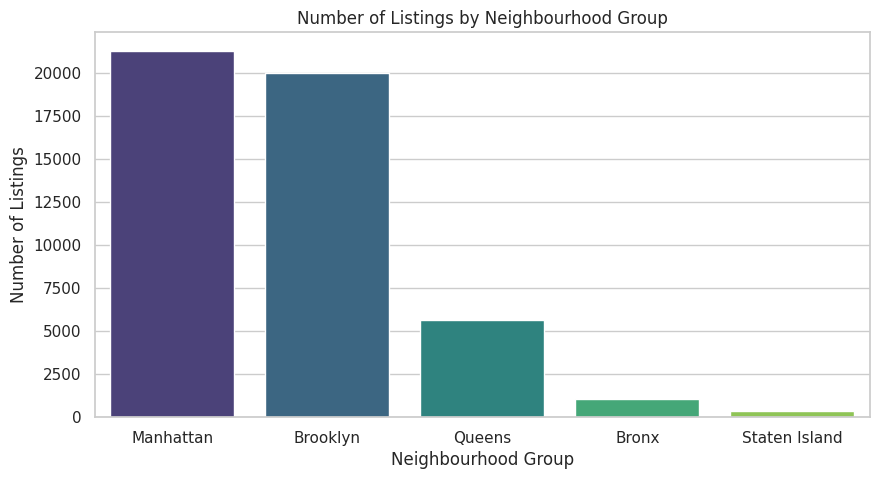

In [15]:
group_counts = df_clean["neighbourhood_group"].value_counts()
print(group_counts)

sns.countplot(data=df_clean, x="neighbourhood_group",
              order=group_counts.index, palette="viridis")
plt.title("Number of Listings by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Number of Listings")
plt.show()

**💡 Insight (apne words me likho):**
*Example:* Manhattan aur Brooklyn milke zyadatar listings cover karte hain. Isse pata chalta hai ki tourists inhi areas me rehna pasand karte hain.

### Q2. Kaunse area me average price sabse zyada hai?

neighbourhood_group
Manhattan        172.90
Brooklyn         115.92
Staten Island     94.24
Queens            94.10
Bronx             83.86
Name: price, dtype: float64


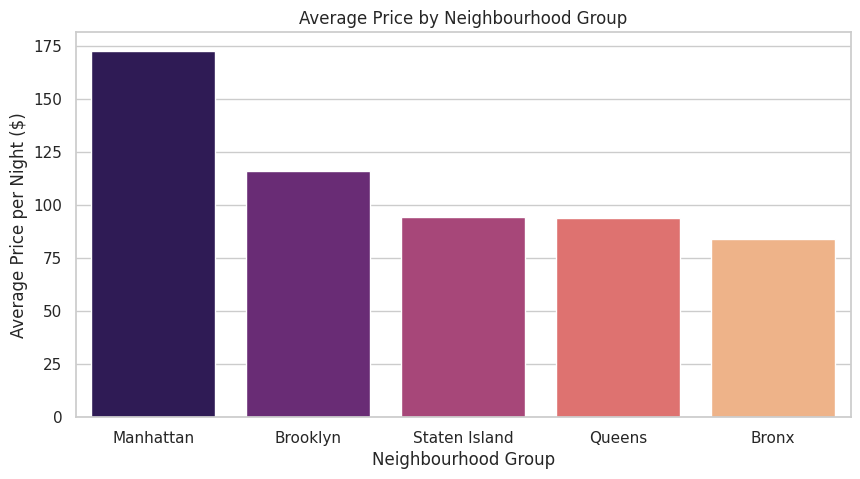

In [16]:
avg_price = (df_clean.groupby("neighbourhood_group")["price"]
             .mean().sort_values(ascending=False).round(2))
print(avg_price)

sns.barplot(x=avg_price.index, y=avg_price.values, palette="magma")
plt.title("Average Price by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Average Price per Night ($)")
plt.show()

**💡 Insight:**
*Example:* Manhattan sabse mehnga area hai. Iska reason hai central location aur tourist attractions ke paas hona.

### Q3. Kaunsa room type sabse popular hai, aur uska price kitna hai?

room_type
Entire home/apt    25022
Private room       22237
Shared room         1151
Name: count, dtype: int64

room_type
Entire home/apt    51.7 %
Private room       45.9 %
Shared room         2.4 %
Name: count, dtype: object


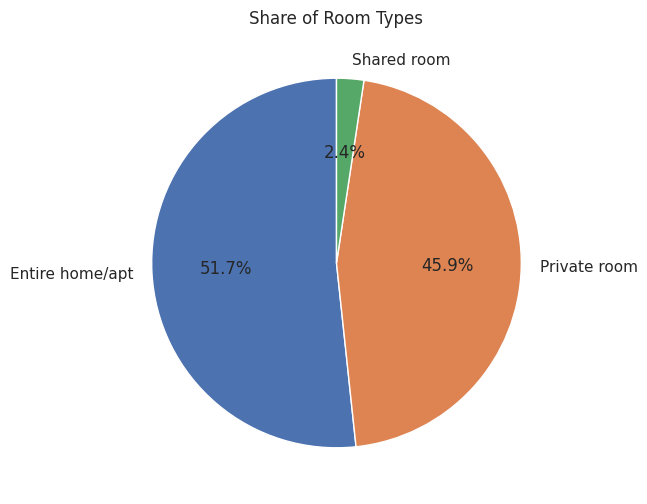

In [17]:
room_counts = df_clean["room_type"].value_counts()
print(room_counts)
print()
print((room_counts / room_counts.sum() * 100).round(1).astype(str) + " %")

plt.figure(figsize=(6, 6))
plt.pie(room_counts.values, labels=room_counts.index,
        autopct="%1.1f%%", startangle=90)
plt.title("Share of Room Types")
plt.show()

room_type
Entire home/apt    189.10
Private room        83.39
Shared room         64.20
Name: price, dtype: float64


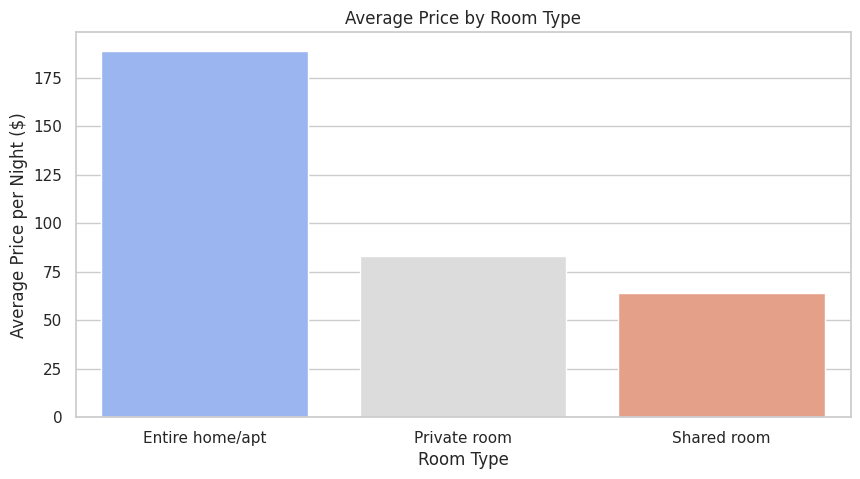

In [18]:
room_price = df_clean.groupby("room_type")["price"].mean().sort_values(ascending=False).round(2)
print(room_price)

sns.barplot(x=room_price.index, y=room_price.values, palette="coolwarm")
plt.title("Average Price by Room Type")
plt.ylabel("Average Price per Night ($)")
plt.xlabel("Room Type")
plt.show()

**💡 Insight:**
*Example:* Entire home/apt sabse zyada hai aur sabse mehnga bhi. Shared room bahut kam hain, matlab demand ya supply dono kam hai.

### Q4. Price kaise distribute hua hai? (Boxplot)

**Boxplot kaise padhein:**
- Dabbe ke beech ki line = **median** (beech ki value)
- Dabba = data ka beech wala 50%
- Bahar ke dots = outliers

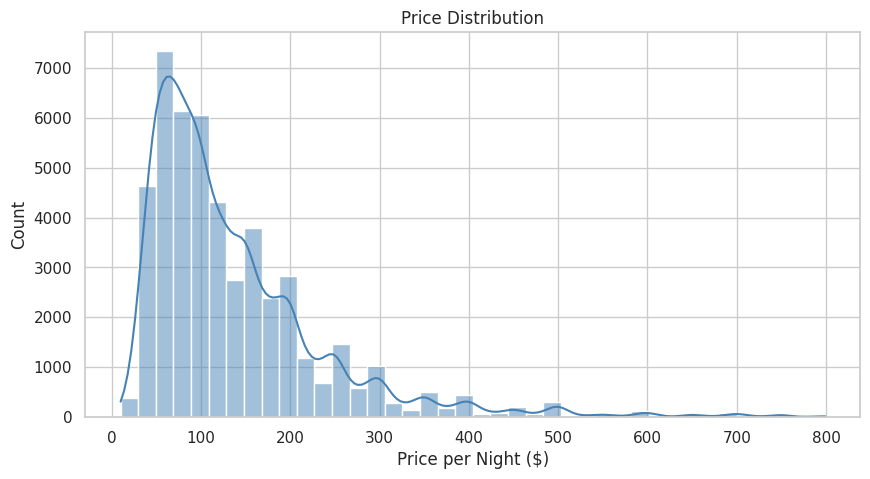

In [19]:
plt.figure(figsize=(10, 5))
sns.histplot(df_clean["price"], bins=40, kde=True, color="steelblue")
plt.title("Price Distribution")
plt.xlabel("Price per Night ($)")
plt.show()

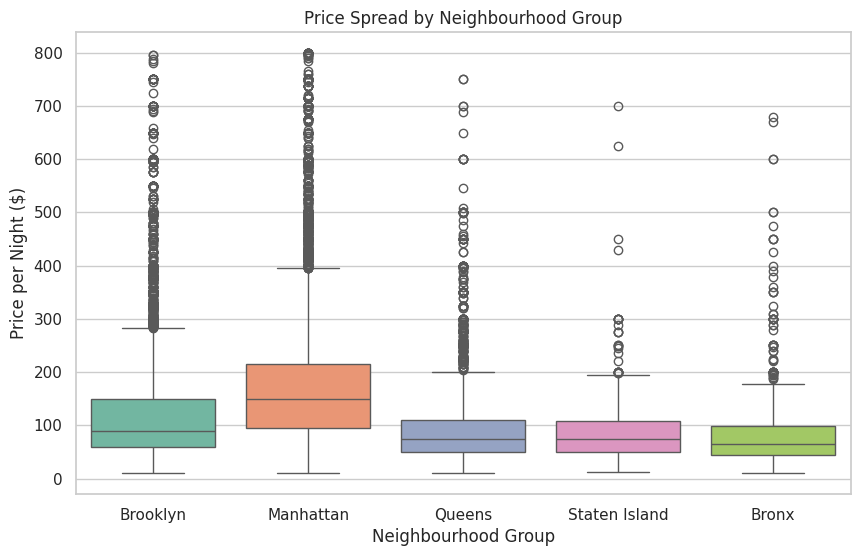

In [20]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=df_clean, x="neighbourhood_group", y="price", palette="Set2")
plt.title("Price Spread by Neighbourhood Group")
plt.xlabel("Neighbourhood Group")
plt.ylabel("Price per Night ($)")
plt.show()

**💡 Insight:**
*Example:* Zyadatar listings sasti hain aur kuch hi mehngi hain (right-skewed distribution). Manhattan ka box sabse upar hai, matlab wahan price ka range bhi zyada hai.

### Q5. Top 10 neighbourhoods (sabse zyada listings)

neighbourhood
Williamsburg          3904
Bedford-Stuyvesant    3694
Harlem                2645
Bushwick              2458
Hell's Kitchen        1936
Upper West Side       1928
East Village          1835
Upper East Side       1773
Crown Heights         1559
Midtown               1503
Name: count, dtype: int64


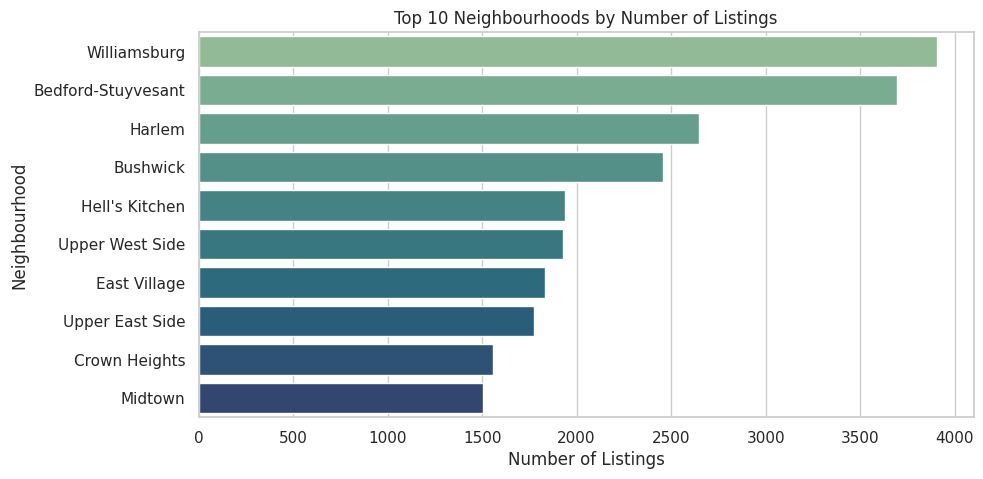

In [21]:
top_neigh = df_clean["neighbourhood"].value_counts().head(10)
print(top_neigh)

sns.barplot(x=top_neigh.values, y=top_neigh.index, palette="crest")
plt.title("Top 10 Neighbourhoods by Number of Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Neighbourhood")
plt.show()

### Q6. Sabse mehnge neighbourhoods (jahan kam se kam 30 listings hon)

neighbourhood
Tribeca               295.65
NoHo                  276.25
Flatiron District     258.16
Midtown               255.75
SoHo                  229.83
West Village          224.90
Financial District    215.75
Theater District      214.23
Chelsea               212.74
Murray Hill           210.23
Name: mean, dtype: float64


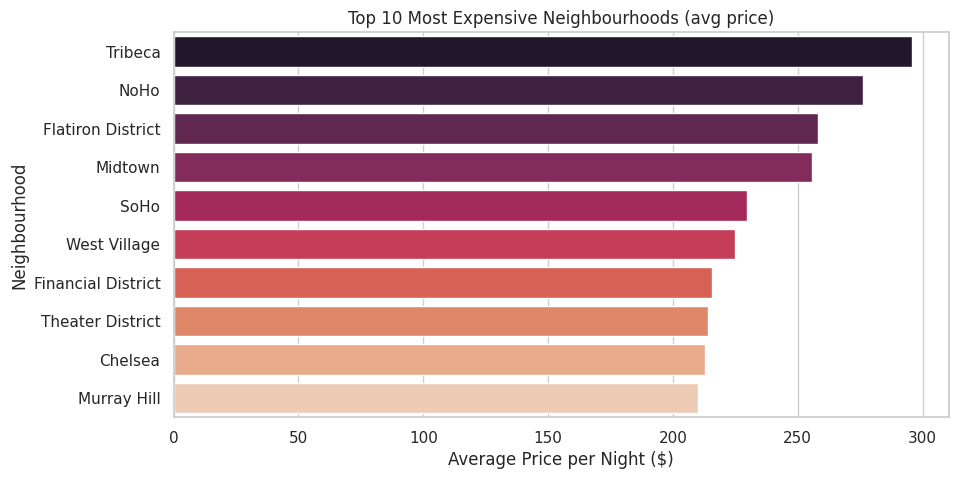

In [22]:
neigh_stats = df_clean.groupby("neighbourhood")["price"].agg(["mean", "count"])
neigh_stats = neigh_stats[neigh_stats["count"] >= 30]          # chhote sample ko hatao
top_expensive = neigh_stats["mean"].sort_values(ascending=False).head(10).round(2)
print(top_expensive)

sns.barplot(x=top_expensive.values, y=top_expensive.index, palette="rocket")
plt.title("Top 10 Most Expensive Neighbourhoods (avg price)")
plt.xlabel("Average Price per Night ($)")
plt.ylabel("Neighbourhood")
plt.show()

**💡 Insight:** (Top 10 list dekhke likho — kya yeh areas Manhattan ke hain? Kya pattern dikha?)

### Q7. Top 10 hosts (jinke paas sabse zyada listings hain)

host_id    host_name        
219517861  Sonder (NYC)         327
107434423  Blueground           232
30283594   Kara                 117
137358866  Kazuya               103
16098958   Jeremy & Laura        96
12243051   Sonder                96
61391963   Corporate Housing     91
22541573   Ken                   87
200380610  Pranjal               65
7503643    Vida                  52
dtype: int64


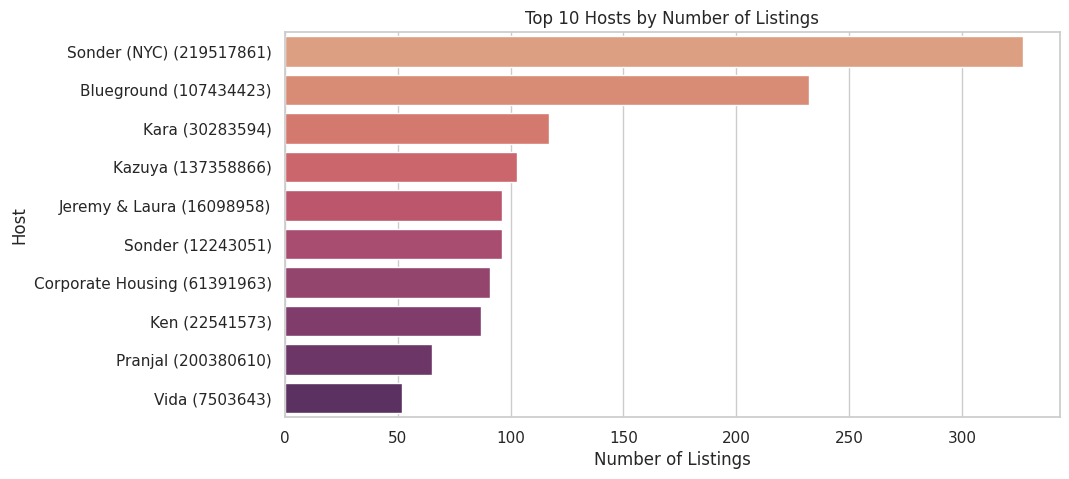

In [23]:
top_hosts = (df_clean.groupby(["host_id", "host_name"])
             .size().sort_values(ascending=False).head(10))
print(top_hosts)

host_plot = top_hosts.reset_index()
host_plot.columns = ["host_id", "host_name", "listings"]
host_plot["label"] = host_plot["host_name"] + " (" + host_plot["host_id"].astype(str) + ")"

sns.barplot(data=host_plot, x="listings", y="label", palette="flare")
plt.title("Top 10 Hosts by Number of Listings")
plt.xlabel("Number of Listings")
plt.ylabel("Host")
plt.show()

**💡 Insight:**
*Example:* Kuch hosts ke paas 50+ listings hain. Yeh individual log nahi balki professional property managers ya companies ho sakti hain.

### Q8. Availability aur price me koi relation hai?

`availability_365` = saal me kitne din listing book karne ke liye khuli hai.

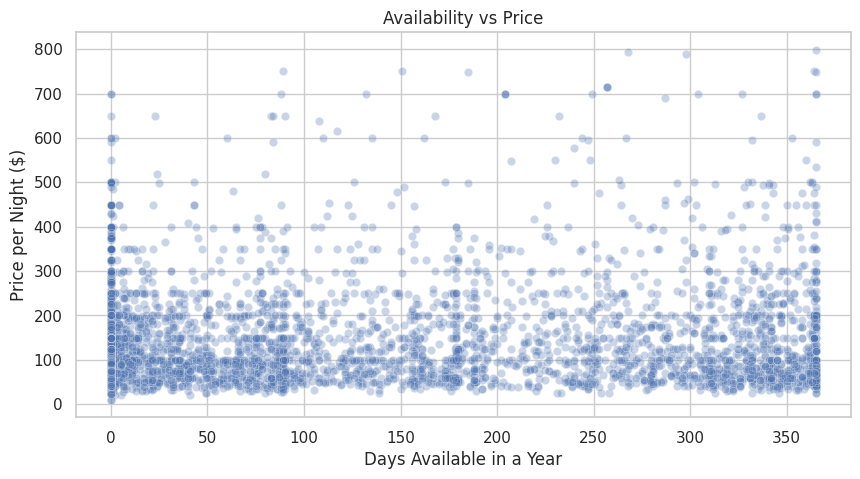

In [24]:
sample = df_clean.sample(min(5000, len(df_clean)), random_state=42)   # chart jaldi bane isliye sample

sns.scatterplot(data=sample, x="availability_365", y="price", alpha=0.3)
plt.title("Availability vs Price")
plt.xlabel("Days Available in a Year")
plt.ylabel("Price per Night ($)")
plt.show()

In [25]:
# Availability ko groups (bins) me todke average price dekhte hain
df_clean["availability_group"] = pd.cut(
    df_clean["availability_365"],
    bins=[-1, 0, 90, 180, 270, 365],
    labels=["0 days", "1-90", "91-180", "181-270", "271-365"]
)
print(df_clean.groupby("availability_group")["price"].mean().round(2))

availability_group
0 days     125.07
1-90       132.70
91-180     143.39
181-270    158.65
271-365    153.08
Name: price, dtype: float64


**💡 Insight:** (Kya zyada available listings mehngi hain ya sasti? Likho jo dikha.)

### Q9. Minimum nights me outliers

Kuch listings me minimum nights 365 ya usse zyada hai. Aisi listings tourists ke liye nahi, long-term rent ke liye hain.

count    48410.000000
mean         6.979508
std         20.293249
min          1.000000
25%          1.000000
50%          3.000000
75%          5.000000
max       1250.000000
Name: minimum_nights, dtype: float64

Listings with minimum_nights > 30  : 718
Listings with minimum_nights > 365 : 14


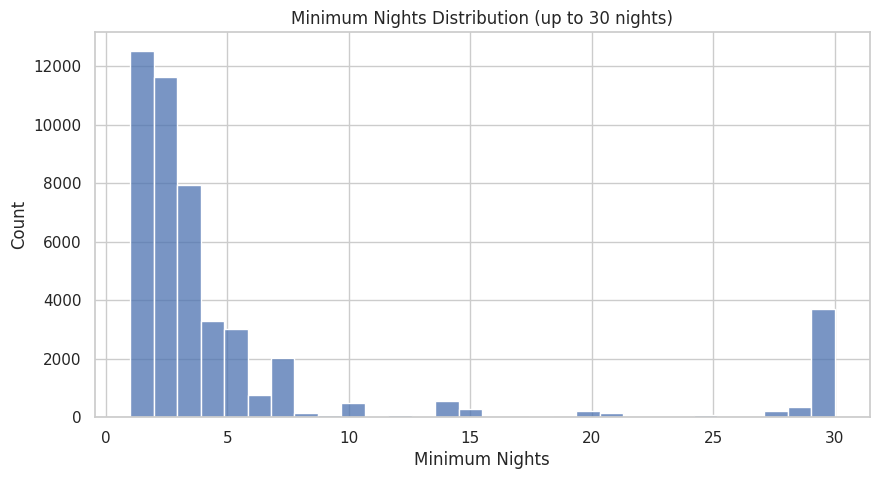

In [26]:
print(df_clean["minimum_nights"].describe())
print()
print("Listings with minimum_nights > 30  :", (df_clean["minimum_nights"] > 30).sum())
print("Listings with minimum_nights > 365 :", (df_clean["minimum_nights"] > 365).sum())

plt.figure(figsize=(10, 5))
sns.histplot(df_clean[df_clean["minimum_nights"] <= 30]["minimum_nights"], bins=30)
plt.title("Minimum Nights Distribution (up to 30 nights)")
plt.xlabel("Minimum Nights")
plt.show()

**💡 Insight:**
*Example:* Zyadatar listings 1 se 7 raat ki minimum stay maangti hain. 30+ nights wali listings monthly rentals ki tarah kaam karti hain.

### Q10. Reviews aur price ka relation + Correlation heatmap

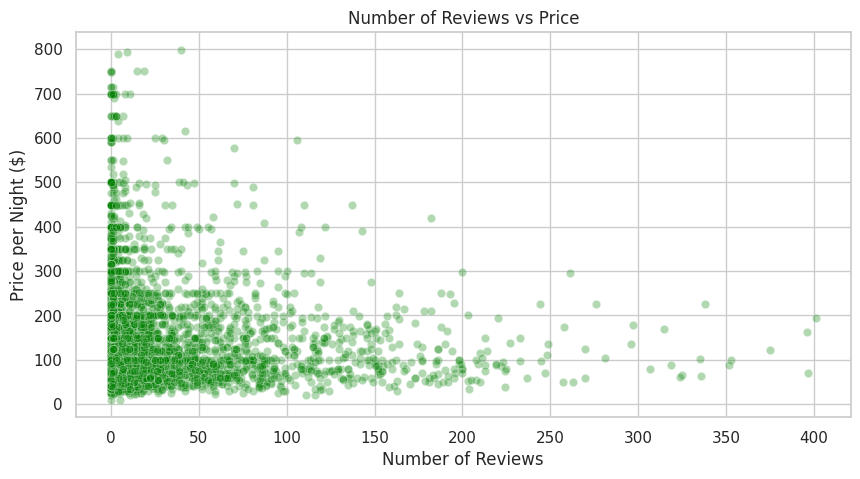

In [27]:
sns.scatterplot(data=sample, x="number_of_reviews", y="price", alpha=0.3, color="green")
plt.title("Number of Reviews vs Price")
plt.xlabel("Number of Reviews")
plt.ylabel("Price per Night ($)")
plt.show()

**Correlation** batata hai ki do numbers saath me kaise badalte hain:
- `+1` → ek badhta hai to doosra bhi badhta hai
- `-1` → ek badhta hai to doosra ghatta hai
- `0` → koi relation nahi

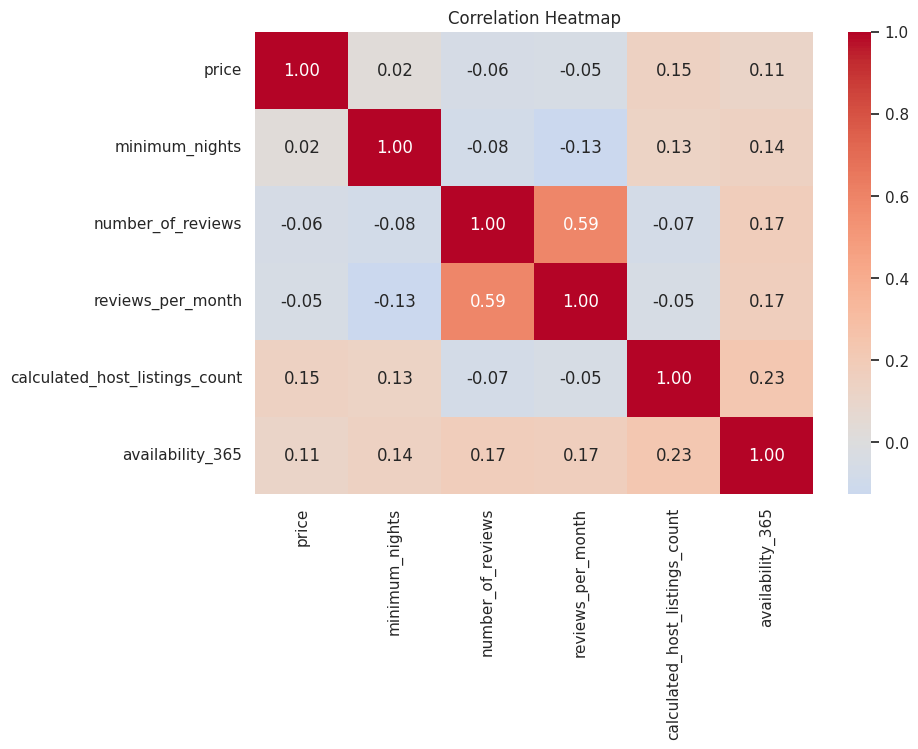

In [28]:
num_cols = ["price", "minimum_nights", "number_of_reviews",
            "reviews_per_month", "calculated_host_listings_count", "availability_365"]

plt.figure(figsize=(9, 6))
sns.heatmap(df_clean[num_cols].corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap")
plt.show()

**💡 Insight:**
*Example:* `number_of_reviews` aur `reviews_per_month` me strong positive correlation hai (jo expected hai). Price kisi bhi numeric column se strongly correlated nahi hai, matlab price location aur room type pe zyada depend karta hai.

### Bonus 🗺️ — Price ka map

Latitude/longitude ko x-y axis maan ke plot karne se New York ka mini-map ban jata hai.

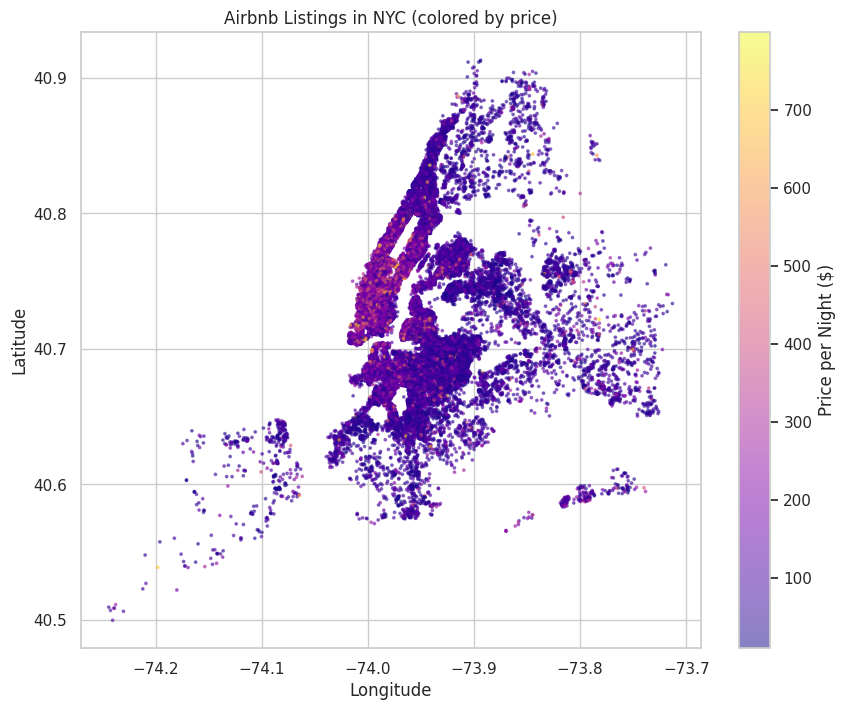

In [29]:
plt.figure(figsize=(10, 8))
sc = plt.scatter(df_clean["longitude"], df_clean["latitude"],
                 c=df_clean["price"], cmap="plasma", s=3, alpha=0.5)
plt.colorbar(sc, label="Price per Night ($)")
plt.title("Airbnb Listings in NYC (colored by price)")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()